# Anna Lee C. Iijima: Logistic Regression Location Model

Model trained only on reviews written by Anna Lee C. Iijima. She mostly covers New York (Finger Lakes, Long Island)
and Germany, plus a long tail of Eastern European countries, and Riesling is her main grape in both places.
Uses the same train / val / test splits as `tfidf_baselines.ipynb`.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from joblib import parallel_config
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.multiclass import OneVsRestClassifier

SEED = 42
AUTHOR = "Anna Lee C. Iijima"
TARGETS = ["country", "province", "region_1"]
MIN_TRAIN_REVIEWS = 20       # lower than the global 70, since she has ~2.8k training reviews
GLOBAL_MIN_TRAIN_REVIEWS = 70
N_JOBS = 6 #change depending on number of cores
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})

## Load

In [2]:
split_dir = Path("data_clean/splits")
full = {name: pd.read_parquet(split_dir / f"{name}.parquet") for name in ["train", "val", "test"]}
train, val, test = (full[name][full[name]["taster_name"] == AUTHOR].reset_index(drop=True)
                    for name in ["train", "val", "test"])
len(train), len(val), len(test)

(2838, 578, 601)

## What she reviews

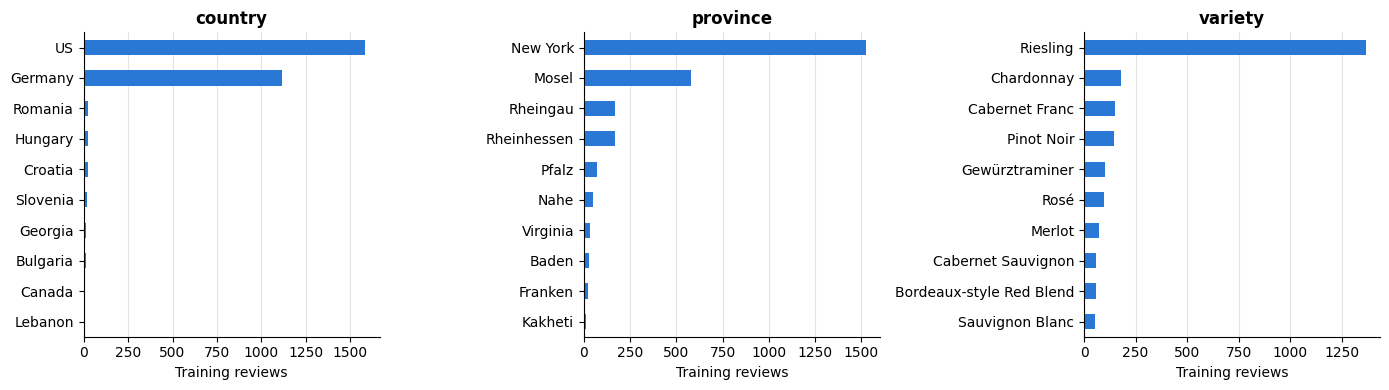

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["country", "province", "variety"]):
    train[col].value_counts().head(10).sort_values().plot.barh(color=BLUE, ax=ax)
    ax.set(title=col, xlabel="Training reviews", ylabel="")
    ax.grid(axis="y", visible=False)
plt.tight_layout()

In [4]:
pd.crosstab(train["variety"], train["country"]).loc[
    train["variety"].value_counts().head(8).index, ["US", "Germany"]]

country,US,Germany
variety,,
Riesling,442,919
Chardonnay,173,2
Cabernet Franc,151,0
Pinot Noir,99,34
Gewürztraminer,86,14
Rosé,81,7
Merlot,70,0
Cabernet Sauvignon,51,0


## TF-IDF features (fit on her reviews only)

In [5]:
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)
X_train = vectorizer.fit_transform(train["description"])
X_val = vectorizer.transform(val["description"])
X_test = vectorizer.transform(test["description"])
X_train.shape

(2838, 8341)

## Targets

In [6]:
keep = {}
summary = []
for target in TARGETS:
    counts = train[target].value_counts()
    keep[target] = counts[counts >= MIN_TRAIN_REVIEWS].index
    summary.append({
        "target": target,
        "all_classes": train[target].nunique(),
        "kept_classes": len(keep[target]),
        "pct_missing": train[target].isna().mean() * 100,
        "pct_rows_kept": train[target].isin(keep[target]).mean() * 100,
    })
pd.DataFrame(summary).set_index("target").round(1)

,all_classes,kept_classes,pct_missing,pct_rows_kept
target,,,,
country,16,5,0.0,97.6
province,62,9,0.0,93.1
region_1,28,8,43.9,54.2


In [7]:
{target: list(classes) for target, classes in keep.items()}

{'country': ['US', 'Germany', 'Romania', 'Croatia', 'Hungary'],
 'province': ['New York',
  'Mosel',
  'Rheingau',
  'Rheinhessen',
  'Pfalz',
  'Nahe',
  'Virginia',
  'Baden',
  'Franken'],
 'region_1': ['Finger Lakes',
  'North Fork of Long Island',
  'Seneca Lake',
  'New York',
  'Cayuga Lake',
  'Hudson River Region',
  'Long Island',
  'Virginia']}

In [8]:
def subset(split, X, target):
    mask = split[target].isin(keep[target]).to_numpy()
    return X[mask], split[target].to_numpy()[mask]

## Tuning C and class weights

Two picks per target from the same grid: the settings with the best validation **accuracy**, and the
settings with the best validation **macro-F1** (which rewards getting the small countries / provinces right).
Macro-F1 is always averaged over her kept classes only.

In [9]:
grid = [{"C": C, "class_weight": cw} for cw in [None, "balanced"] for C in [0.3, 1, 3, 10, 30, 100]]
tuning = []
for target in TARGETS:
    Xt, yt = subset(train, X_train, target)
    Xv, yv = subset(val, X_val, target)
    for params in grid:
        pred = LogisticRegression(max_iter=5000, **params).fit(Xt, yt).predict(Xv)
        tuning.append({
            "target": target,
            "C": params["C"],
            "class_weight": params["class_weight"] or "none",
            "accuracy": accuracy_score(yv, pred),
            "macro_F1": f1_score(yv, pred, labels=keep[target], average="macro", zero_division=0),
        })
tuning = pd.DataFrame(tuning)
best = pd.concat({metric: tuning.loc[tuning.groupby("target")[metric].idxmax()].set_index("target").loc[TARGETS]
                  for metric in ["accuracy", "macro_F1"]}, names=["picked_by"])
best.round(3)

C class_weight  accuracy  macro_F1
picked_by target                                         
accuracy  country   30.0     balanced     0.766     0.469
          province   1.0         none     0.694     0.160
          region_1  10.0     balanced     0.616     0.215
macro_F1  country    1.0     balanced     0.761     0.599
          province   1.0     balanced     0.604     0.265
          region_1   0.3     balanced     0.401     0.220

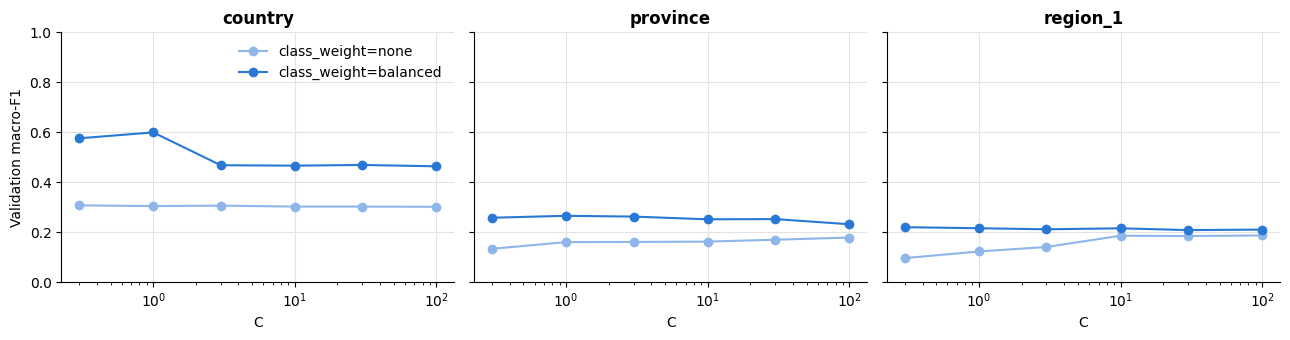

In [10]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(13, 3.5), sharey=True)
for ax, target in zip(axes, TARGETS):
    for cw, color in [("none", "#8fb6e8"), ("balanced", BLUE)]:
        rows = tuning[(tuning["target"] == target) & (tuning["class_weight"] == cw)]
        ax.plot(rows["C"], rows["macro_F1"], marker="o", color=color, label=f"class_weight={cw}")
    ax.set(title=target, xscale="log", xlabel="C", ylim=(0, 1))
axes[0].set_ylabel("Validation macro-F1")
axes[0].legend(frameon=False)
plt.tight_layout()

## Author model vs baselines

* **Most frequent**: always guess her most common class.
* **General model**: the logistic regression from `tfidf_baselines.ipynb`, trained on every taster's reviews
  (her own included), evaluated on her validation reviews.
* **Author model (best accuracy / best macro-F1)**: logistic regression trained only on her reviews,
  with the two tuned settings above.

In [11]:
VARIANTS = {"accuracy": "Author model (best accuracy)", "macro_F1": "Author model (best macro-F1)"}
author_models = {}
for (metric, target), params in best.iterrows():
    cw = None if params["class_weight"] == "none" else params["class_weight"]
    Xt, yt = subset(train, X_train, target)
    author_models[target, metric] = LogisticRegression(C=params["C"], class_weight=cw, max_iter=5000).fit(Xt, yt)

In [12]:
full_train = full["train"]
global_vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=20000)
X_full_train = global_vectorizer.fit_transform(full_train["description"])
global_models = {}
for target in TARGETS:
    counts = full_train[target].value_counts()
    mask = full_train[target].isin(counts[counts >= GLOBAL_MIN_TRAIN_REVIEWS].index).to_numpy()
    model = OneVsRestClassifier(LogisticRegression(C=10, solver="liblinear"), n_jobs=N_JOBS)
    with parallel_config(max_nbytes=None):
        model.fit(X_full_train[mask], full_train[target].to_numpy()[mask])
    global_models[target] = model

In [13]:
def evaluate(split, X, target):
    Xs, ys = subset(split, X, target)
    descriptions = split.loc[split[target].isin(keep[target]), "description"]
    Xt, yt = subset(train, X_train, target)
    preds = {
        "Most frequent (dummy)": DummyClassifier(strategy="most_frequent").fit(Xt, yt).predict(Xs),
        "General model (all tasters)": global_models[target].predict(global_vectorizer.transform(descriptions)),
        **{label: author_models[target, metric].predict(Xs) for metric, label in VARIANTS.items()},
    }
    return [{
        "target": target,
        "model": name,
        "accuracy": accuracy_score(ys, pred),
        "macro_F1": f1_score(ys, pred, labels=keep[target], average="macro", zero_division=0),
    } for name, pred in preds.items()]

results = pd.DataFrame([row for t in TARGETS for row in evaluate(val, X_val, t)]).set_index(["target", "model"])
results.round(3)

accuracy  macro_F1
target   model                                           
country  Most frequent (dummy)            0.539     0.140
         General model (all tasters)      0.741     0.301
         Author model (best accuracy)     0.766     0.469
         Author model (best macro-F1)     0.761     0.599
province Most frequent (dummy)            0.561     0.080
         General model (all tasters)      0.651     0.179
         Author model (best accuracy)     0.694     0.160
         Author model (best macro-F1)     0.604     0.265
region_1 Most frequent (dummy)            0.548     0.088
         General model (all tasters)      0.565     0.142
         Author model (best accuracy)     0.616     0.215
         Author model (best macro-F1)     0.401     0.220

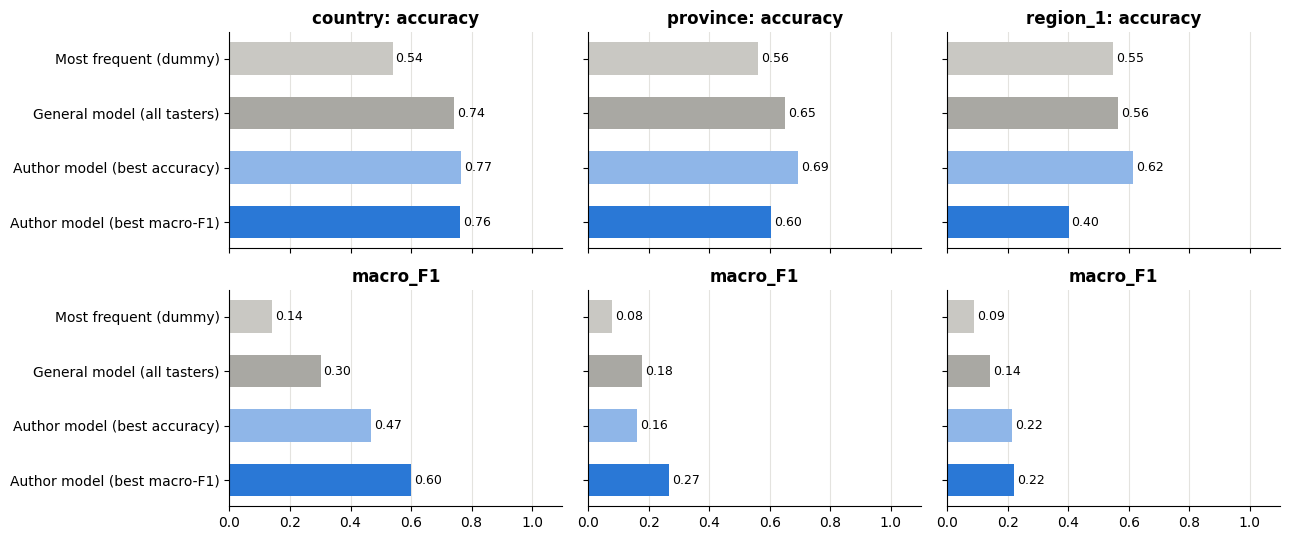

In [14]:
fig, axes = plt.subplots(2, len(TARGETS), figsize=(13, 5.5), sharex=True)
colors = ["#c9c8c3", "#a9a8a3", "#8fb6e8", BLUE]
for row, metric in enumerate(["accuracy", "macro_F1"]):
    for ax, target in zip(axes[row], TARGETS):
        vals = results.loc[target, metric]
        ax.barh(vals.index, vals, color=colors, height=0.6)
        ax.invert_yaxis()
        for i, v in enumerate(vals):
            ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
        ax.set(title=f"{target}: {metric}" if row == 0 else metric, xlim=(0, 1.1))
        ax.grid(axis="y", visible=False)
for ax in axes[:, 1:].flat:
    ax.tick_params(labelleft=False)
plt.tight_layout()

## Confusion matrices (validation)

From here on, `author` is the best macro-F1 (class-balanced) model, since it actually predicts the small classes.

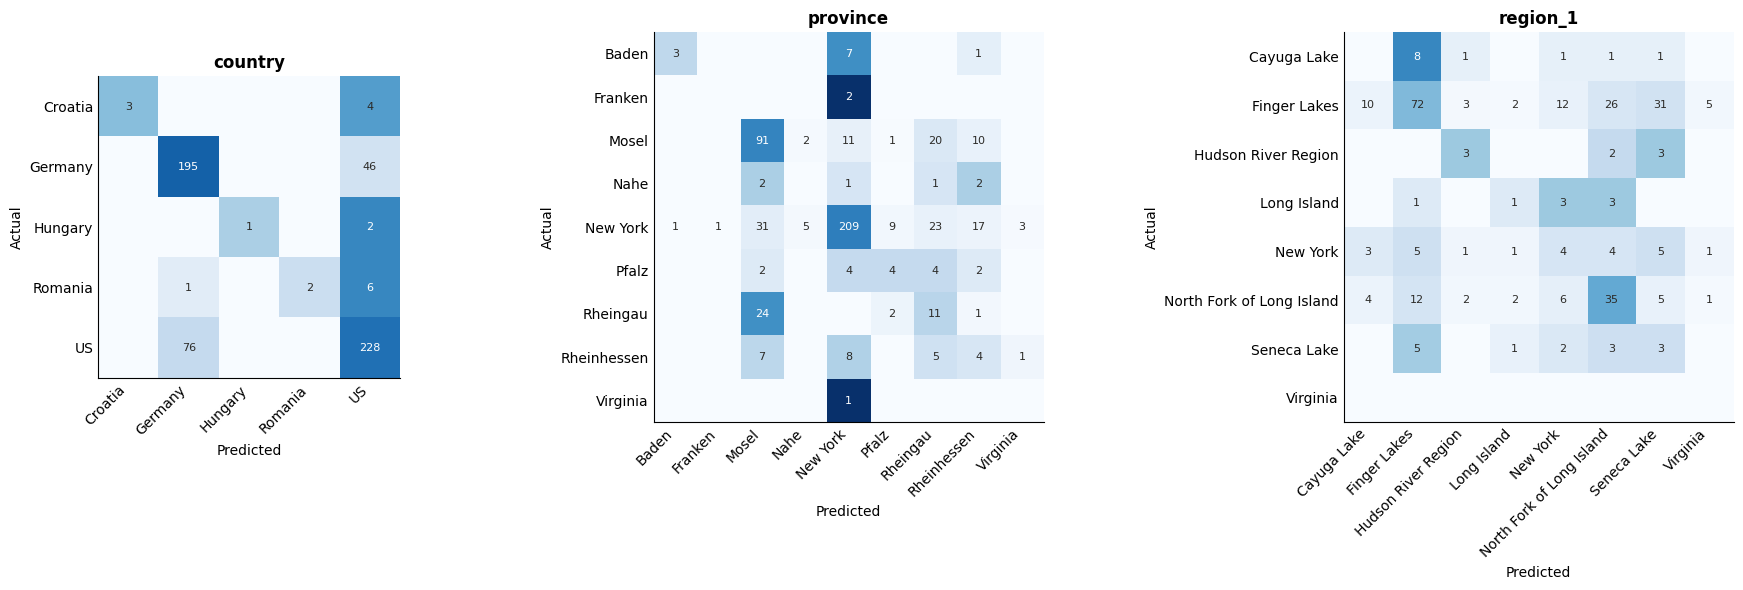

In [15]:
author = {target: author_models[target, "macro_F1"] for target in TARGETS}

def plot_confusion(target, ax):
    Xv, yv = subset(val, X_val, target)
    labels = author[target].classes_
    cm = confusion_matrix(yv, author[target].predict(Xv), labels=labels)
    share = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i, j in np.ndindex(cm.shape):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if share[i, j] > 0.6 else "#2b2a27")
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set(title=target, xlabel="Predicted", ylabel="Actual")
    ax.grid(False)
    ax.tick_params(length=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 1.6, 1.6]})
for ax, target in zip(axes, TARGETS):
    plot_confusion(target, ax)
plt.tight_layout()

In [16]:
per_class = []
for target in TARGETS:
    Xv, yv = subset(val, X_val, target)
    correct = author[target].predict(Xv) == yv
    per_class.append(pd.DataFrame({"target": target, "actual": yv, "correct": correct})
                     .groupby(["target", "actual"])["correct"].agg(["size", "mean"]))
pd.concat(per_class).rename(columns={"mean": "accuracy"}).round(3)

size  accuracy
target   actual                                   
country  Croatia                       7     0.429
         Germany                     241     0.809
         Hungary                       3     0.333
         Romania                       9     0.222
         US                          304     0.750
province Baden                        11     0.273
         Franken                       2     0.000
         Mosel                       135     0.674
         Nahe                          6     0.000
         New York                    299     0.699
         Pfalz                        16     0.250
         Rheingau                     38     0.289
         Rheinhessen                  25     0.160
         Virginia                      1     0.000
region_1 Cayuga Lake                  12     0.000
         Finger Lakes                161     0.447
         Hudson River Region           8     0.375
         Long Island                   8     0.125
         New York                     24     0.167
         North Fork of Long Island    67     0.522
         Seneca Lake                  14     0.214

## Most predictive words

In [17]:
words = vectorizer.get_feature_names_out()

def top_words(model, n=8):
    return pd.DataFrame({cls: words[np.argsort(coef)[::-1][:n]]
                         for cls, coef in zip(model.classes_, model.coef_)}).T

top_words(author["country"])

,0,1,2,3,4,5,6,7
Croatia,croatian,malvasia,flower,grassy,hay,note,aeration,at 13
Germany,riesling,mineral,kabinett,now,spätlese,through,dry riesling,sweet
Hungary,tokaji,honey,has,hefty,tokaj,hefty dose,peel,orange peel
Romania,romanian,romania,from romania,brisk acidity,green,noir is,wine concentrated,for
US,chardonnay,franc,cabernet franc,apple,cabernet,gewürztraminer,in,bit


[Text(0.5, 1.0, 'Words most associated with each province (Anna Lee C. Iijima)'),
 Text(0.5, 0, 'Rank within province')]

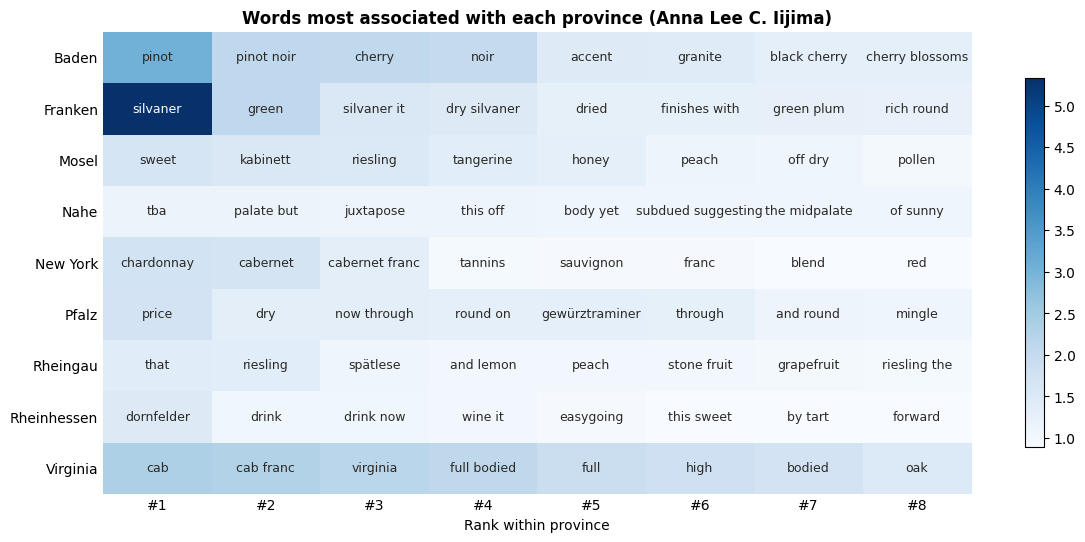

In [18]:
model = author["province"]
top_idx = np.argsort(model.coef_, axis=1)[:, ::-1][:, :8]
top_coefs = np.take_along_axis(model.coef_, top_idx, axis=1)
fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(top_coefs, cmap="Blues", aspect="auto")
threshold = top_coefs.min() + (top_coefs.max() - top_coefs.min()) * 0.6
for i, j in np.ndindex(top_coefs.shape):
    ax.text(j, i, words[top_idx[i, j]], ha="center", va="center", fontsize=9,
            color="white" if top_coefs[i, j] > threshold else "#2b2a27")
ax.set_xticks(range(8), [f"#{k + 1}" for k in range(8)])
ax.set_yticks(range(len(model.classes_)), model.classes_)
ax.tick_params(length=0)
ax.grid(False)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set(title=f"Words most associated with each province ({AUTHOR})", xlabel="Rank within province")

In [19]:
top_words(author["region_1"])

,0,1,2,3,4,5,6,7
Cayuga Lake,concentrated with,richly,fresh,dry,pith,fresh apple,floral,and floral
Finger Lakes,riesling,off dry,dry,on this,off,lime,riesling it,peach
Hudson River Region,seyval,seyval blanc,hudson,mingle,hudson river,or,river,candied
Long Island,chalky,oak,roth,now with,soft chalky,and flavor,rosé,unusual
New York,bramble and,slightly,brambly,moderately,grapes,noir,bramble,pinot
North Fork of Long Island,sauvignon,merlot,sauvignon blanc,island,long island,cabernet,acidity and,tannins
Seneca Lake,riesling,luscious,mineral,cutting,wiemer,crushed mineral,of white,to
Virginia,virginia,cab,cab franc,full bodied,full,high,virginia cab,oak


## Does the review just name the place?

Accuracy split by whether the true province name appears in the review text.

In [20]:
mask = val["province"].isin(keep["province"])
province_val = val[mask].copy()
province_val["predicted"] = author["province"].predict(X_val[mask.to_numpy()])
province_val["correct"] = province_val["predicted"] == province_val["province"]
province_val["names_province"] = [p.lower() in d.lower()
                                  for p, d in zip(province_val["province"], province_val["description"])]
province_val.groupby("names_province")["correct"].agg(["size", "mean"]).rename(columns={"mean": "accuracy"}).round(3)

,size,accuracy
names_province,,
False,527,0.605
True,6,0.500


In [21]:
province_val.groupby("province")["names_province"].mean().sort_values(ascending=False).round(3)

province
Mosel          0.037
Rheingau       0.026
Baden          0.000
Nahe           0.000
Franken        0.000
New York       0.000
Pfalz          0.000
Rheinhessen    0.000
Virginia       0.000
Name: names_province, dtype: float64

## Riesling: New York vs Germany

Riesling is her main grape on both sides of the Atlantic, so the grape name alone can't separate them.
A binary model on Rieslings only shows what she writes differently about each.

In [22]:
def riesling_rows(split):
    return (split["variety"].eq("Riesling") & split["country"].isin(["US", "Germany"])).to_numpy()

rt, rv = riesling_rows(train), riesling_rows(val)
yt_r, yv_r = train.loc[rt, "country"], val.loc[rv, "country"]
riesling_acc = {C: accuracy_score(yv_r, LogisticRegression(C=C, max_iter=5000).fit(X_train[rt], yt_r).predict(X_val[rv]))
                for C in [0.3, 1, 3, 10, 30, 100]}
best_C = max(riesling_acc, key=riesling_acc.get)
riesling_model = LogisticRegression(C=best_C, max_iter=5000).fit(X_train[rt], yt_r)
pd.Series({
    "train Rieslings": rt.sum(),
    "val Rieslings": rv.sum(),
    "best C": best_C,
    "always guess Germany": yv_r.eq("Germany").mean(),
    "Riesling-only model": riesling_acc[best_C],
    "country model (best accuracy)": accuracy_score(yv_r, author_models["country", "accuracy"].predict(X_val[rv])),
    "country model (best macro-F1)": accuracy_score(yv_r, author["country"].predict(X_val[rv])),
}).round(3)

train Rieslings                  1361.000
val Rieslings                     291.000
best C                              1.000
always guess Germany                0.691
Riesling-only model                 0.735
country model (best accuracy)       0.732
country model (best macro-F1)       0.742
dtype: float64

In [23]:
coef = riesling_model.coef_[0]      # positive = classes_[1]
order = np.argsort(coef)
n = 12
side = pd.DataFrame({
    riesling_model.classes_[0]: words[order[:n]],
    riesling_model.classes_[1]: words[order[::-1][:n]],
})
side

,Germany,US
0,kabinett,apple
1,spätlese,riesling
2,through,pressed
3,sweet,apples
4,tangerine,semidry
5,saffron,dry
6,now through,lime
7,mineral,light
8,mouthfeel,semidry riesling
9,now,apple and


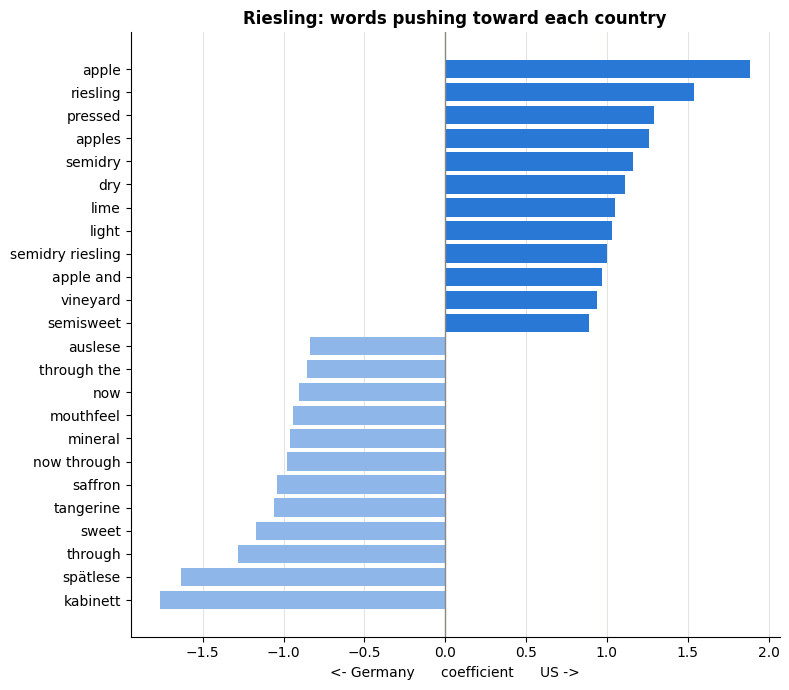

In [24]:
show = np.r_[order[:n], order[::-1][:n][::-1]]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(words[show], coef[show], color=["#8fb6e8"] * n + [BLUE] * n)
ax.axvline(0, color="#8a8984", linewidth=1)
ax.grid(axis="y", visible=False)
ax.set(title="Riesling: words pushing toward each country",
       xlabel=f"<- {riesling_model.classes_[0]}      coefficient      {riesling_model.classes_[1]} ->")
plt.tight_layout()

## Most common mistakes

In [25]:
province_val.loc[~province_val["correct"], ["province", "predicted"]].value_counts().head(10).rename("reviews").to_frame()

reviews
province    predicted           
New York    Mosel             31
Rheingau    Mosel             24
New York    Rheingau          23
Mosel       Rheingau          20
New York    Rheinhessen       17
Mosel       New York          11
            Rheinhessen       10
New York    Pfalz              9
Rheinhessen New York           8
Baden       New York           7

In [26]:
pd.set_option("display.max_colwidth", 300)
province_val.loc[~province_val["correct"], ["province", "predicted", "variety", "description"]].head(5)

,province,predicted,variety,description
1,New York,Rheingau,Riesling,"This pretty, aromatic Riesling is lush with cherry-blossom and berry scents that mingle lusciously into layers of wax and lanolin. By contrast, the palate is crisp and bracing with tones of lemon and lime acidity."
7,New York,Rheingau,Riesling,"An extravagantly perfumed Riesling billowing with white jasmine and elderflower notes. The floral tones are maintained on the palate as well, but interlaced with notes of stone and slate that add richness and complexity. The finish is dry and elegant, ending with a hint of bitter lime pith."
8,New York,Rheingau,Riesling,"Benefits of bottle aging show well in this late release by Shaw. Clean and minerally with a shower of freshly squeezed lemon and honeysuckle on the nose, this almost dry Riesling is lush with honey and white peaches on the palate. There's a sleek backbone of steel and slate that adds elegance to..."
9,Mosel,Rheinhessen,Riesling,Vivacious notes of yellow plum and pear are shaded in tones of savory herb and earth in this dry light-bodied Riesling. Lemon and tart tangerine acidity jolt the midpalate into a brisk finish. Drink now.
14,New York,Rheinhessen,Tocai Friulano,"Boisterously fruity and aromatic, this full-bodied white offers a bounty of luscious peach, pineapple and mango flavors. It's voluptuously ripe yet briskly balanced, finishing on a crisp mineral tone. Drink now through 2018 to capture the essence of its fresh, fruity style."


## Test set

In [27]:
test_results = pd.DataFrame([row for t in TARGETS for row in evaluate(test, X_test, t)]).set_index(["target", "model"])
test_results.round(3)

accuracy  macro_F1
target   model                                           
country  Most frequent (dummy)            0.545     0.141
         General model (all tasters)      0.729     0.294
         Author model (best accuracy)     0.769     0.310
         Author model (best macro-F1)     0.767     0.360
province Most frequent (dummy)            0.551     0.079
         General model (all tasters)      0.607     0.167
         Author model (best accuracy)     0.646     0.148
         Author model (best macro-F1)     0.589     0.365
region_1 Most frequent (dummy)            0.539     0.088
         General model (all tasters)      0.584     0.197
         Author model (best accuracy)     0.575     0.212
         Author model (best macro-F1)     0.448     0.332


## Findings

* **Who she is.** 56% New York, 39% Germany, and the rest is a long tail of Eastern European countries. Riesling is about
  half of her reviews and she writes about it on both sides (919 German, 442 New York in train).
* **Country.** The author-only model gets ~77% accuracy on val and test, beating "always US" (54%) and slightly beating the
  general model trained on every taster (73-74%). With balanced class weights it also picks up her small countries
  (val macro-F1 0.60 vs 0.30 for the general model), but those classes have under 10 val reviews each, so on test the
  macro-F1 drops to 0.36. Treat the small-country numbers as noisy.
* **Province.** The unweighted author model is best for accuracy (69% val / 65% test vs 61-65% for the general model).
  Balancing classes trades ~9 points of accuracy for much better macro-F1 (0.27 to 0.37). Most errors are New York vs
  German regions and German regions confused with each other (Mosel / Rheingau / Rheinhessen).
* **region_1 is barely learnable.** Her regions are nested (Seneca Lake and Cayuga Lake sit inside the Finger Lakes,
  which sit inside New York) and 44% of her reviews have no region at all, so even the best model only beats the
  dummy by a few points.
* **She almost never names the place.** Under 4% of reviews mention the true province, so the model is not just
  reading place names. It learns grapes (Chardonnay, Cabernet Franc point to New York) and German wine-law terms
  (Kabinett, Spätlese, Auslese point to Germany), which give the location away almost as well.
* **Riesling is the hard case.** On Rieslings alone a dedicated model reaches 73.5%, only 4 points above always
  guessing Germany (69%). German Rieslings get *Prädikat* terms, "sweet", "saffron", "tangerine" and "drink now through";
  New York ones get "semidry / semisweet", "dry", "apple", "lime", "pressed" and "light". Her tasting vocabulary
  barely changes between the two, so most of the signal comes from labeling terms rather than flavor words.
